# Data Augmentation


The objectives of this lab session are the following:
- Visualize augmented data samples
- Experiment with Data Augmentation

All experiments done on CIFAR10.


# What Is Data Augmentation?
Data augmentation is the process of creating new training examples by modifying existing ones. 

The key idea is to introduce variety in a way that doesn’t change the meaning of the data.

In image classification, this might mean flipping an image, rotating it slightly, or changing its brightness.

The image still shows the same object, and the label stays the same. In other fields, the idea is similar. For natural language processing, you might reword a sentence. In audio, you might change the pitch or add background noise.

These changes are helpful because most machine learning models are sensitive to small details. 

A slight shift in color or shape can throw them off if they haven’t seen enough variation during training. 

Augmentation exposes the model to different versions of the same concept. Over time, the model learns to focus on patterns that stay consistent, rather than those that change.

This process builds robustness. A model trained with good augmentations can handle new, unseen data more confidently. It has learned not just what the data looks like, but how it can vary.

However, not every change is useful. If you rotate the digit “6” too far, it may look like a “9.” If you crop too much of an image, you might cut out the object entirely. Good augmentations increase diversity without breaking the connection between input and label. This balance is essential.

## Visualization of DA

**Data augmentation (DA) in Pytorch is done when defining the Dataset class. In order to enable DA, the class must accept a transforms argument, which will dynamically modify the original data samples by applying them a function.** 

**Most of the time, this function is a composition of several functions.** 


In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data.dataloader import DataLoader
from torchvision.datasets import CIFAR10

# Types of Data Augmentation
Not all augmentations do the same thing. Some change how the image looks, others modify where objects appear. Some add noise, while others combine images together. It helps to group these techniques by what they do and why you’d use them. [link](https://docs.pytorch.org/vision/main/transforms.html)

## Geometric Transformations
These change the spatial layout of the image. They help the model become less sensitive to position, scale, and orientation.

Examples:

* ``HorizontalFlip``, ``VerticalFlip``: Mirror images along axes.
* ``RandomRotation``: Rotate by small degrees to simulate angle variation.
* ``RandomCrop``, ``CenterCrop``: Train the model to handle partial views.
* ``Affine``, ``Perspective``: Apply broader spatial distortions.

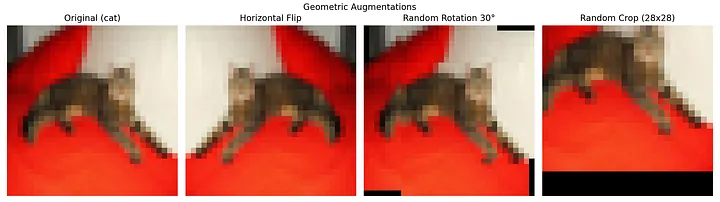

### RandomCrop
**which crops the image at a random location and pads the borders** [link](https://pytorch.org/vision/main/generated/torchvision.transforms.RandomCrop.html)

In [33]:
transforms.RandomCrop?

Init signature:
transforms.RandomCrop(
    size,
    padding=None,
    pad_if_needed=False,
    fill=0,
    padding_mode='constant',
)
Docstring:     
Crop the given image at a random location.
If the image is torch Tensor, it is expected
to have [..., H, W] shape, where ... means an arbitrary number of leading dimensions,
but if non-constant padding is used, the input is expected to have at most 2 leading dimensions

Args:
    size (sequence or int): Desired output size of the crop. If size is an
        int instead of sequence like (h, w), a square crop (size, size) is
        made. If provided a sequence of length 1, it will be interpreted as (size[0], size[0]).
    padding (int or sequence, optional): Optional padding on each border
        of the image. Default is None. If a single int is provided this
        is used to pad all borders. If sequence of length 2 is provided this is the padding
        on left/right and top/bottom respectively. If a sequence of length 4 is provided


In [9]:
transform_RandomCrop = transforms.Compose([
    transforms.RandomCrop((28,28), padding=(5,10), padding_mode='constant'),
    #transforms.RandomCrop((28,28), padding=(10,5), padding_mode='edge'),
    #transforms.RandomCrop((32,32), padding=(10,10), padding_mode='constant',fill =255),
    transforms.ToTensor(),
    ##transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    ])

rootdir = './data'

#dataset
c10RandomCrop = CIFAR10(rootdir,train=True,download=True,transform=transform_RandomCrop)

loader = DataLoader(c10RandomCrop,batch_size=4,shuffle=True) ### Shuffle to False so that we always see the same images


**Let's do a figure for each batch**

(4, 3, 28, 28)


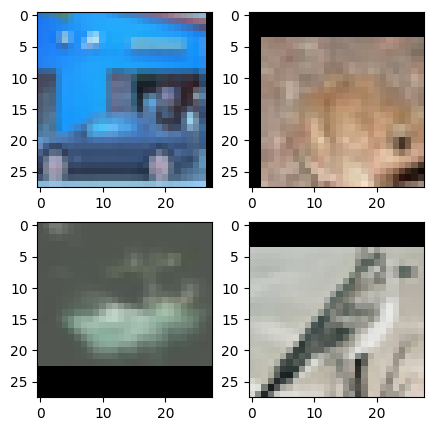

In [10]:
from matplotlib import pyplot as plt
f = plt.figure(figsize=(5,5))

for i,(data,target) in enumerate(loader):
    
    data = (data.numpy())
    print(data.shape)
    plt.subplot(2,2,1)
    plt.imshow(data[0].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,2)
    plt.imshow(data[1].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,3)
    plt.imshow(data[2].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,4)
    plt.imshow(data[3].swapaxes(0,2).swapaxes(0,1))

    break

f.savefig('train_DARandomCrop.png')

### CenterCrop
**Crop the input at the center.** [link](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.v2.CenterCrop.html#torchvision.transforms.v2.CenterCrop)

In [7]:
transforms.CenterCrop?

Init signature: transforms.CenterCrop(size)
Docstring:     
Crops the given image at the center.
If the image is torch Tensor, it is expected
to have [..., H, W] shape, where ... means an arbitrary number of leading dimensions.
If image size is smaller than output size along any edge, image is padded with 0 and then center cropped.

Args:
    size (sequence or int): Desired output size of the crop. If size is an
        int instead of sequence like (h, w), a square crop (size, size) is
        made. If provided a sequence of length 1, it will be interpreted as (size[0], size[0]).
Init docstring: Initialize internal Module state, shared by both nn.Module and ScriptModule.
File:           c:\python\python313\lib\site-packages\torchvision\transforms\transforms.py
Type:           type
Subclasses:     

In [11]:
transform_CenterCrop = transforms.Compose([
    transforms.CenterCrop((32,32)),
    transforms.ToTensor(),
    ])

rootdir = './data'

c10trainFlip = CIFAR10(rootdir,train=True,download=True,transform=transform_CenterCrop)

loaderFlip = DataLoader(c10trainFlip,batch_size=4,shuffle=False) ### Shuffle to False so that we always see the same images

(4, 3, 32, 32)


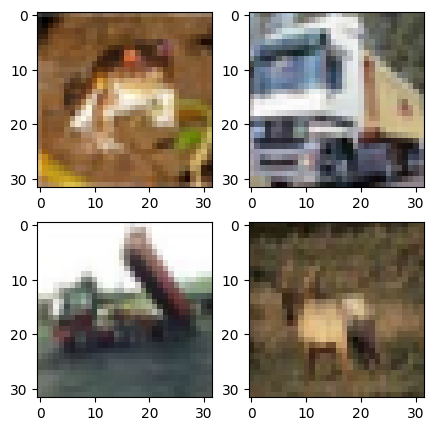

In [12]:
from matplotlib import pyplot as plt
f = plt.figure(figsize=(5,5))

for i,(data,target) in enumerate(loaderFlip):
    
    data = (data.numpy())
    print(data.shape)
    plt.subplot(2,2,1)
    plt.imshow(data[0].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,2)
    plt.imshow(data[1].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,3)
    plt.imshow(data[2].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,4)
    plt.imshow(data[3].swapaxes(0,2).swapaxes(0,1))

    break

f.savefig('train_DACenterCrop.png')

## RandomHorizontalFlip
**Horizontally flip the given image randomly with a given probability.** [link](https://pytorch.org/vision/main/generated/torchvision.transforms.RandomHorizontalFlip.html#torchvision.transforms.RandomHorizontalFlip)

In [13]:
transforms.RandomHorizontalFlip?

Init signature: transforms.RandomHorizontalFlip(p=0.5)
Docstring:     
Horizontally flip the given image randomly with a given probability.
If the image is torch Tensor, it is expected
to have [..., H, W] shape, where ... means an arbitrary number of leading
dimensions

Args:
    p (float): probability of the image being flipped. Default value is 0.5
Init docstring: Initialize internal Module state, shared by both nn.Module and ScriptModule.
File:           c:\python\python3\lib\site-packages\torchvision\transforms\transforms.py
Type:           type
Subclasses:     

In [15]:
transform_RandomHorizontalFlip = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    ##transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

rootdir = './data'

c10trainFlip = CIFAR10(rootdir,train=True,download=True,transform=transform_RandomHorizontalFlip)

loaderFlip = DataLoader(c10trainFlip,batch_size=4,shuffle=False) ### Shuffle to False so that we always see the same images

**Let's do a figure for each batch**

(4, 3, 32, 32)


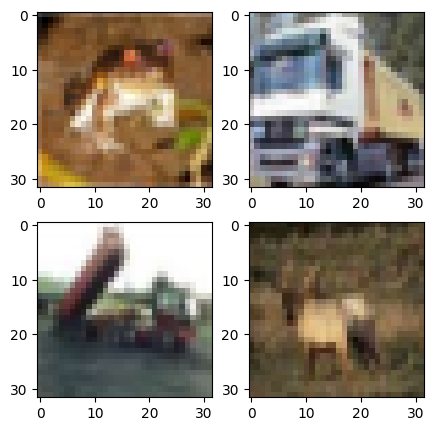

In [16]:
from matplotlib import pyplot as plt
f = plt.figure(figsize=(5,5))

for i,(data,target) in enumerate(loaderFlip):
    
    data = (data.numpy())
    print(data.shape)
    plt.subplot(2,2,1)
    plt.imshow(data[0].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,2)
    plt.imshow(data[1].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,3)
    plt.imshow(data[2].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,4)
    plt.imshow(data[3].swapaxes(0,2).swapaxes(0,1))

    break

f.savefig('train_DARandomHorizontalFlip.png')

## RandomVerticalFlip
**Vertically flip the given image randomly with a given probability.**

In [45]:
transforms.RandomVerticalFlip?

Init signature: transforms.RandomVerticalFlip(p=0.5)
Docstring:     
Vertically flip the given image randomly with a given probability.
If the image is torch Tensor, it is expected
to have [..., H, W] shape, where ... means an arbitrary number of leading
dimensions

Args:
    p (float): probability of the image being flipped. Default value is 0.5
Init docstring: Initialize internal Module state, shared by both nn.Module and ScriptModule.
File:           c:\python\python3\lib\site-packages\torchvision\transforms\transforms.py
Type:           type
Subclasses:     

In [17]:
transform_RandomVerticalFlip = transforms.Compose([
    transforms.RandomVerticalFlip(0.5),
    transforms.ToTensor(),
    ##transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

rootdir = './data'

c10trainVFlip = CIFAR10(rootdir,train=True,download=True,transform=transform_RandomVerticalFlip)

loaderVFlip = DataLoader(c10trainVFlip,batch_size=4,shuffle=False) ### Shuffle to False so that we always see the same images

**Let's do a figure for each batch**

(4, 3, 32, 32)


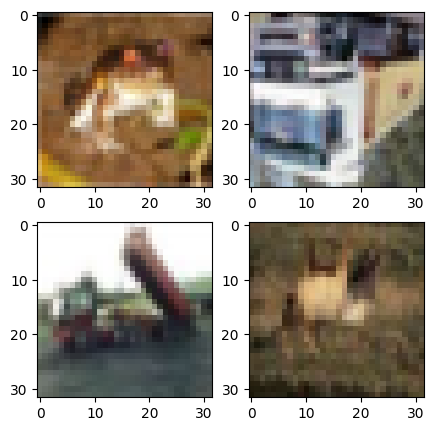

In [18]:
from matplotlib import pyplot as plt
f = plt.figure(figsize=(5,5))

for i,(data,target) in enumerate(loaderVFlip):
    
    data = (data.numpy())
    print(data.shape)
    plt.subplot(2,2,1)
    plt.imshow(data[0].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,2)
    plt.imshow(data[1].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,3)
    plt.imshow(data[2].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,4)
    plt.imshow(data[3].swapaxes(0,2).swapaxes(0,1))

    break

f.savefig('train_DARandomVerticalFlip.png')

## 2.Color and Appearance Adjustments
These simulate changes in lighting, sensors, or image quality. They help the model learn to ignore pixel-level variations.

**Examples**:

* `ColorJitter`: Adjusts brightness, contrast, saturation, hue.
* `Grayscale`: Removes color information completely.
* `GaussianBlur`, `Noise`: Mimics sensor blur or environmental interference.
* `Posterize`, `Solarize`: Change pixel intensity patterns.

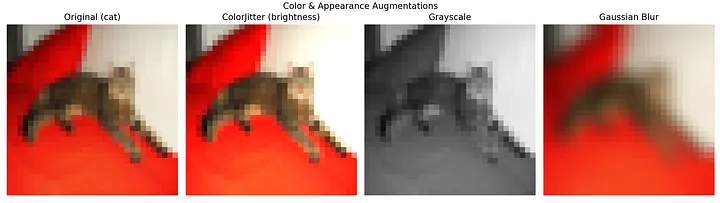

In [8]:
transforms.Grayscale?

Init signature: transforms.Grayscale(num_output_channels=1)
Docstring:     
Convert image to grayscale.
If the image is torch Tensor, it is expected
to have [..., 3, H, W] shape, where ... means an arbitrary number of leading dimensions

Args:
    num_output_channels (int): (1 or 3) number of channels desired for output image

Returns:
    PIL Image: Grayscale version of the input.

    - If ``num_output_channels == 1`` : returned image is single channel
    - If ``num_output_channels == 3`` : returned image is 3 channel with r == g == b
Init docstring: Initialize internal Module state, shared by both nn.Module and ScriptModule.
File:           c:\python\python313\lib\site-packages\torchvision\transforms\transforms.py
Type:           type
Subclasses:     

In [19]:
transform_Grayscale = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    ])

rootdir = './data'

c10train_Grayscale = CIFAR10(rootdir,train=True,download=True,transform=transform_Grayscale)

loader_Grayscale = DataLoader(c10train_Grayscale,batch_size=4,shuffle=False) ### Shuffle to False so that we always see the same images

Batch shape: (4, 1, 32, 32)


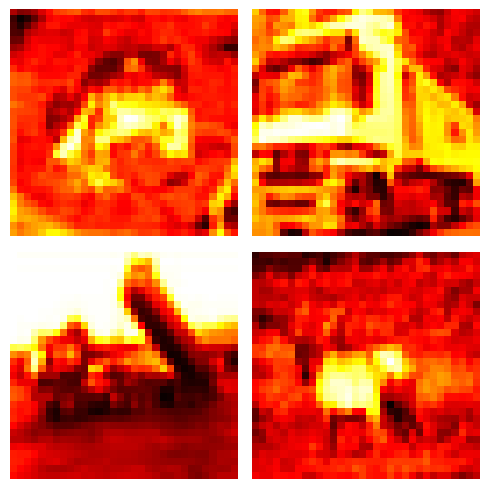

In [21]:
f, axes = plt.subplots(2, 2, figsize=(5, 5))
for data, target in loader_Grayscale:
    data = data.numpy()  # Shape: (4, 1, 32, 32)
    print("Batch shape:", data.shape)

    #print(data)
    # Plot each image in the batch
    for idx, ax in enumerate(axes.flat):
        # Index data[idx, 0] to convert shape from (1, 32, 32) -> (32, 32)
        ax.imshow(data[idx, 0], cmap='gray')
        ax.axis('off')  # Optional: hides axis ticks
        
    break  # Process only the first batch

f.tight_layout()
f.savefig('train_Grayscale.png')
plt.show()

## 3. Occlusion and Region-Based Augmentations
These hide or remove parts of the input to force the model to reason about incomplete data.

**Examples**:

* `Cutout`: Removes a random square from the image.
* `RandomErasing`: Similar to Cutout, with more shape and placement flexibility.
* `Hide-and-Seek`: Blocks out multiple patches at random.

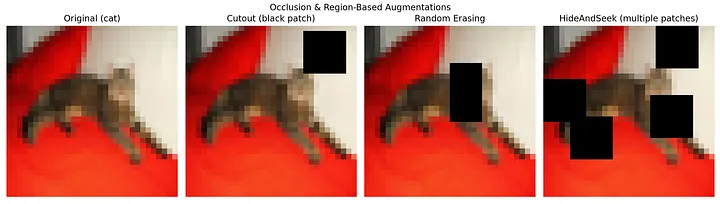

## 4. Sample Mixing Techniques
These blend multiple images and labels to produce new samples. They work as strong regularizers.

**Examples**:

* `Mixup`: Linearly combines two images and their labels.
* `CutMix`: Patches part of one image onto another, mixing labels.
* `FMix`: Uses frequency-based masks to blend inputs more naturally.

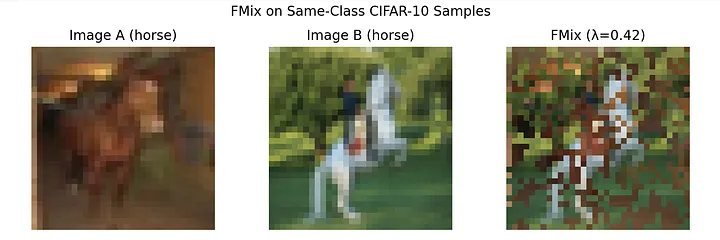

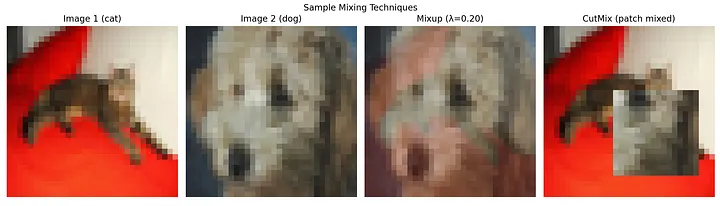

**Note1**:
Although FMix images can appear strange or unrecognizable to us — especially at low resolutions like the CIFAR-10 data — the technique is still highly effective.

**Note2**: 
While Mixup and CutMix are powerful tools, applying them blindly can generate confusing samples — especially when mixing semantically unrelated classes like “dog” and “airplane.” For clearer visualizations (and often better model behavior in early experiments), it helps to restrict mixed samples to the same or related classes.

In [24]:
import torchvision.transforms.v2 as transforms2
transforms2.MixUp?

Init signature:
transforms2.MixUp(
    *,
    alpha: float = 1.0,
    num_classes: Optional[int] = None,
    labels_getter='default',
) -> None
Docstring:     
Apply MixUp to the provided batch of images and labels.

Paper: `mixup: Beyond Empirical Risk Minimization <https://arxiv.org/abs/1710.09412>`_.

.. note::
    This transform is meant to be used on **batches** of samples, not
    individual images. See
    :ref:`sphx_glr_auto_examples_transforms_plot_cutmix_mixup.py` for detailed usage
    examples.
    The sample pairing is deterministic and done by matching consecutive
    samples in the batch, so the batch needs to be shuffled (this is an
    implementation detail, not a guaranteed convention.)

In the input, the labels are expected to be a tensor of shape ``(batch_size,)``. They will be transformed
into a tensor of shape ``(batch_size, num_classes)``.

Args:
    alpha (float, optional): hyperparameter of the Beta distribution used for mixup. Default is 1.
    num_classes (in

In [26]:
transform_Mixup = transforms.Compose([
    transforms2.MixUp(),
    transforms.ToTensor(),
    ])

rootdir = './data'

c10train_Mixup = CIFAR10(rootdir,train=True,download=True,transform=transform_Mixup)

loader_Mixup = DataLoader(c10train_Mixup,batch_size=4,shuffle=False) ### Shuffle to False so that we always see the same images

ValueError: MixUp() does not support PIL images, bounding boxes and masks.

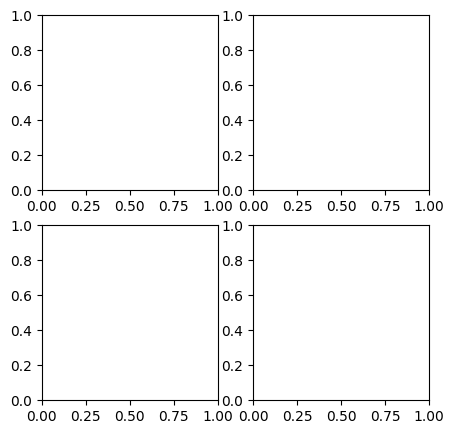

In [27]:
f, axes = plt.subplots(2, 2, figsize=(5, 5))
for data, target in loader_Mixup:
    data = data.numpy()  # Shape: (4, 1, 32, 32)
    print("Batch shape:", data.shape)

    #print(data)
    # Plot each image in the batch
    for idx, ax in enumerate(axes.flat):
        # Index data[idx, 0] to convert shape from (1, 32, 32) -> (32, 32)
        ax.imshow(data[idx, 0], cmap='gray')
        ax.axis('off')  # Optional: hides axis ticks
        
    break  # Process only the first batch

f.tight_layout()
f.savefig('train_GMixUp.png')
plt.show()

## Note:
- Don't forget that you should not change the image size as a result of transformation. 
- There are also some popular packages for data augmentations such as albumentations, including a more detailed pytorch tutorial [here](https://albumentations.ai/docs/examples/pytorch_classification/). You can check out more examples of DA strategies there. 


## Combine of transformations and see the effect

(4, 3, 25, 25)


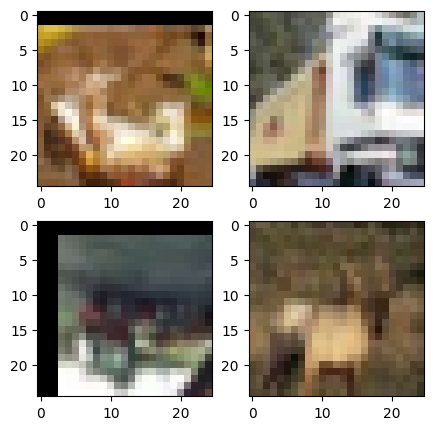

In [22]:
transform_DACombined = transforms.Compose([
    transforms.RandomCrop(25, padding=3),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    ##transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

rootdir = './data'

c10trainDACombined = CIFAR10(rootdir,train=True,download=True,transform=transform_DACombined)

loaderDACombined = DataLoader(c10trainDACombined,batch_size=4,shuffle=False) ### Shuffle to False so that we always see the same images

from matplotlib import pyplot as plt
f = plt.figure(figsize=(5,5))

for i,(data,target) in enumerate(loaderDACombined):
    
    data = (data.numpy())
    print(data.shape)
    plt.subplot(2,2,1)
    plt.imshow(data[0].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,2)
    plt.imshow(data[1].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,3)
    plt.imshow(data[2].swapaxes(0,2).swapaxes(0,1))
    plt.subplot(2,2,4)
    plt.imshow(data[3].swapaxes(0,2).swapaxes(0,1))

    break

f.savefig('train_DACombined.png')